# Air Traffic Data Analysis - Student Exercise
## Inferential Statistics and Regression Analysis

**Student Template - Complete the TODO sections**

In this exercise, you will analyze air traffic data using inferential statistics and regression techniques. Follow the instructions and complete each section marked with `#TODO`.

### Dataset Description:
- **Dom_Pax**: Domestic Air Travel Passengers
- **Int_Pax**: International Air Travel Passengers  
- **Pax**: Total Air Travel Passengers
- **Dom_Flt**: Number of Flights (Domestic)
- **Int_Flt**: Number of Flights (International)
- **Flt**: Number of Flights (Total)
- **Dom_RPM**: Revenue Passenger-miles (Domestic)

## How to run in Colab
1. I open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** and choose this file.
2. I keep the course dataset zip **`air traffic.zip`** in my `C:\Users\sivan\Datasets` folder (I don't unzip it myself).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `air traffic.zip`. The next line unzips it and gives me **`air traffic.csv`**.

(If I run the notebook on my own computer instead of Colab, the upload step is skipped and the zip just needs to be in the same folder as the notebook.)

In [1]:
try:
    from google.colab import files
    uploaded = files.upload()  # Prompts user to select zip file
except ImportError:
    print("Not running in Colab: I use the zip that is already next to this notebook.")
!unzip -o "air traffic.zip"     # Unzips uploaded dataset file

Not running in Colab: I use the zip that is already next to this notebook.
Archive:  air traffic.zip
  inflating: air traffic.csv         


## 1. Setup and Data Loading

In [2]:
# TODO: Import necessary libraries
# Hint: You'll need pandas, numpy, matplotlib, seaborn, scipy.stats, and sklearn modules

# I use pandas and numpy for the table, matplotlib and seaborn for plots,
# scipy.stats for the hypothesis tests, and sklearn for the regression models.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Set up plotting style (optional)
plt.style.use('default')
sns.set_palette("husl")


In [3]:
# TODO: Load the dataset
# Hint: Use pd.read_csv() to load 'air_traffic_data.csv'
# If the file doesn't exist, the code below will create sample data for you

try:
    # Your code to load the dataset:
    # The official course file is 'air traffic.csv' (from 'air traffic.zip').
    # Its numbers are written with commas ("43,032,450"), so I use thousands=',' to read them as numbers.
    df = pd.read_csv('air traffic.csv', thousands=',')
    print("Dataset loaded successfully!")
    print(f"Shape: {df.shape}")
except FileNotFoundError:
    print("Creating sample air traffic data...")
    import numpy as np
    import pandas as pd

    # Create sample data
    np.random.seed(42)
    n_samples = 200

    # Generate correlated data
    dom_flights = np.random.normal(15000, 3000, n_samples)
    int_flights = np.random.normal(8000, 2000, n_samples)

    dom_pax = dom_flights * np.random.normal(12, 2, n_samples) + np.random.normal(0, 10000, n_samples)
    int_pax = int_flights * np.random.normal(15, 3, n_samples) + np.random.normal(0, 15000, n_samples)

    dom_rpm = dom_pax * np.random.normal(800, 100, n_samples)

    # Ensure positive values
    dom_flights = np.abs(dom_flights)
    int_flights = np.abs(int_flights)
    dom_pax = np.abs(dom_pax)
    int_pax = np.abs(int_pax)
    dom_rpm = np.abs(dom_rpm)

    df = pd.DataFrame({
        'Dom_Flt': dom_flights.astype(int),
        'Int_Flt': int_flights.astype(int),
        'Flt': (dom_flights + int_flights).astype(int),
        'Dom_Pax': dom_pax.astype(int),
        'Int_Pax': int_pax.astype(int),
        'Pax': (dom_pax + int_pax).astype(int),
        'Dom_RPM': dom_rpm.astype(int)
    })

    print("Sample data created successfully!")
    print(f"Shape: {df.shape}")

Dataset loaded successfully!
Shape: (249, 17)


## 2. Exploratory Data Analysis

In [4]:
# TODO: Display basic information about the dataset
# Hint: Use df.info(), df.head(), and df.describe() to explore the data

print("Dataset Info:")
# Your code here:
df.info()

print("\nFirst 5 rows:")
# Your code here:
print(df.head())

print("\nBasic Statistics:")
# Your code here:
print(df.describe().T)

# describe() gives me the mean, spread and range of each column, so I can see the scale of the data.
# My data goes month by month, from the first row to the last row:
print(f"\nPeriod covered: {df['Year'].iloc[0]}-{df['Month'].iloc[0]:02d} to {df['Year'].iloc[-1]}-{df['Month'].iloc[-1]:02d} ({len(df)} months)")


Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 17 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Year     249 non-null    int64  
 1   Month    249 non-null    int64  
 2   Dom_Pax  249 non-null    int64  
 3   Int_Pax  249 non-null    int64  
 4   Pax      249 non-null    int64  
 5   Dom_Flt  249 non-null    int64  
 6   Int_Flt  249 non-null    int64  
 7   Flt      249 non-null    int64  
 8   Dom_RPM  249 non-null    int64  
 9   Int_RPM  249 non-null    int64  
 10  RPM      249 non-null    int64  
 11  Dom_ASM  249 non-null    int64  
 12  Int_ASM  249 non-null    int64  
 13  ASM      249 non-null    int64  
 14  Dom_LF   249 non-null    float64
 15  Int_LF   249 non-null    float64
 16  LF       249 non-null    float64
dtypes: float64(3), int64(14)
memory usage: 33.2 KB

First 5 rows:
   Year  Month   Dom_Pax  Int_Pax       Pax  Dom_Flt  Int_Flt     Flt  \
0  2003      1  43032450  4905

In [5]:
# TODO: Check for missing values and handle them if necessary
# Hint: Use df.isnull().sum() to check for missing values
# If there are missing values, decide whether to drop them (dropna()) or fill them (fillna())

print("Missing values:")
# Your code here:
print(df.isnull().sum())

# Handle missing values if any
if df.isnull().sum().sum() > 0:
    print("\nHandling missing values...")
    df = df.dropna()
    print(f"New shape after handling missing values: {df.shape}")
else:
    print("\nI have no missing values, so I keep all the rows.")

Missing values:
Year       0
Month      0
Dom_Pax    0
Int_Pax    0
Pax        0
Dom_Flt    0
Int_Flt    0
Flt        0
Dom_RPM    0
Int_RPM    0
RPM        0
Dom_ASM    0
Int_ASM    0
ASM        0
Dom_LF     0
Int_LF     0
LF         0
dtype: int64

I have no missing values, so I keep all the rows.


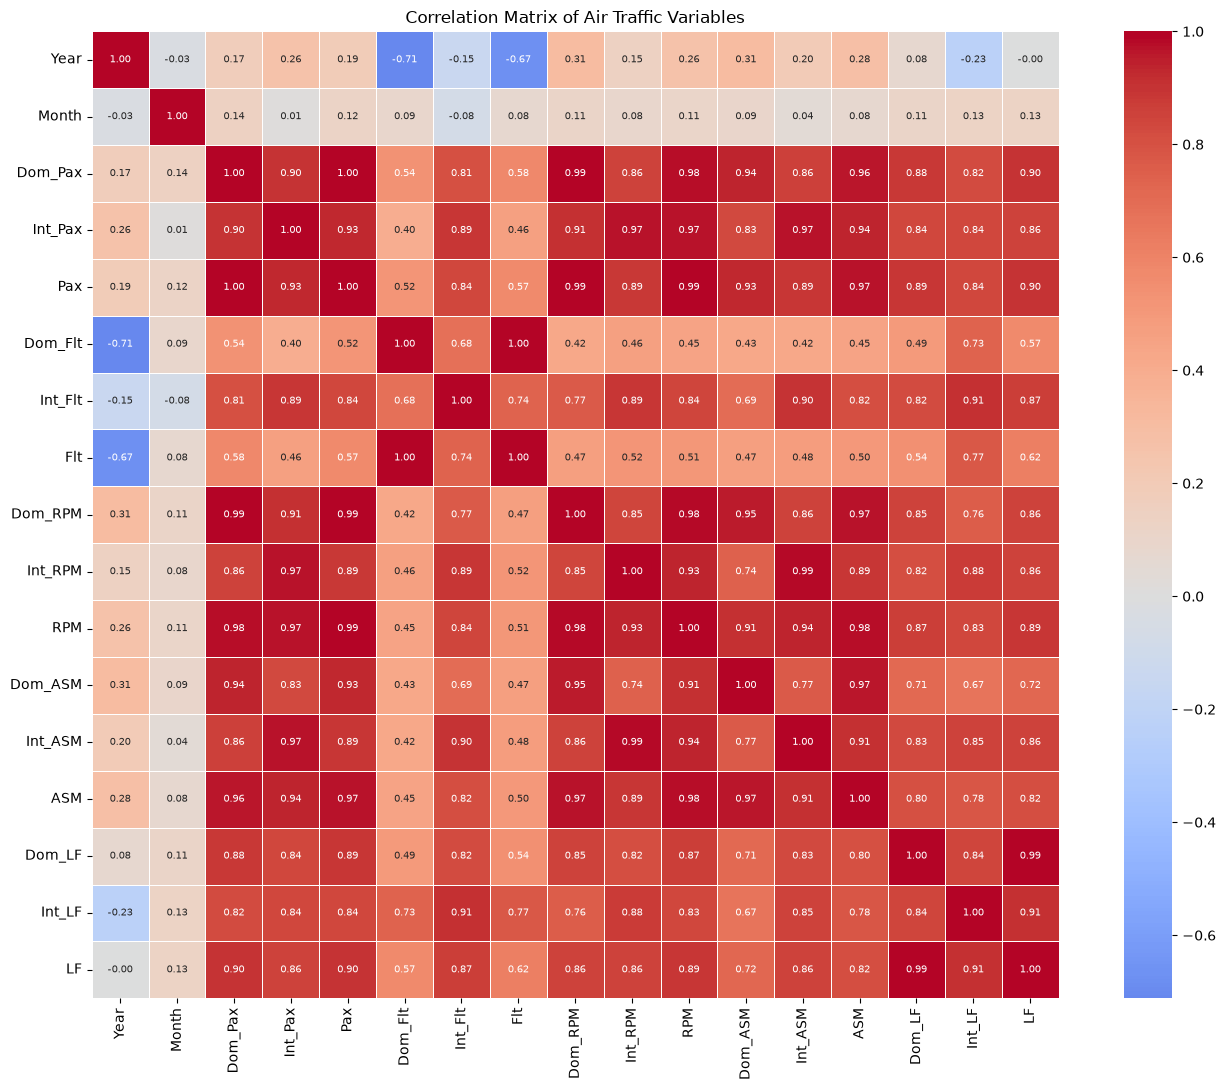

Strongest correlations:
81 of 136 pairs have |r| > 0.7. The top 10:
Dom_Pax  Pax        0.997
Dom_Flt  Flt        0.997
Dom_LF   LF         0.990
Pax      Dom_RPM    0.989
         RPM        0.988
Dom_Pax  Dom_RPM    0.988
Int_RPM  Int_ASM    0.986
Dom_RPM  RPM        0.980
RPM      ASM        0.977
Dom_Pax  RPM        0.976
dtype: float64

The correlations with my target, Pax (total passengers):
Dom_Pax    0.997
Dom_RPM    0.989
RPM        0.988
ASM        0.971
Dom_ASM    0.931
Int_Pax    0.930
LF         0.901
Int_ASM    0.891
Dom_LF     0.888
Int_RPM    0.886
Int_LF     0.837
Int_Flt    0.836
Flt        0.570
Dom_Flt    0.521
Year       0.189
Month      0.119
Name: Pax, dtype: float64


In [6]:
# TODO: Create and analyze correlation matrix
# Hint: Use df.corr() to calculate correlations and sns.heatmap() to visualize

plt.figure(figsize=(14, 11))
# Calculate correlation matrix:
correlation_matrix = df.corr()

# Create heatmap:
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', annot_kws={'size': 7},
            cmap='coolwarm', center=0, square=True, linewidths=0.5)

plt.title('Correlation Matrix of Air Traffic Variables')
plt.tight_layout()
plt.show()

# TODO: Find and print the strongest correlations
# Hint: Look at the correlation matrix values (excluding diagonal)
print("Strongest correlations:")
# Your analysis here:
# I keep only the upper triangle so every pair appears once and the diagonal (always 1) is removed.
upper_triangle_mask = np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
correlation_pairs = correlation_matrix.where(upper_triangle_mask).stack().dropna()
correlation_pairs = correlation_pairs.sort_values(key=abs, ascending=False)
strong_pairs = correlation_pairs[correlation_pairs.abs() > 0.7]
print(f"{len(strong_pairs)} of {len(correlation_pairs)} pairs have |r| > 0.7. The top 10:")
print(strong_pairs.head(10).round(3))

print("\nThe correlations with my target, Pax (total passengers):")
print(correlation_matrix['Pax'].drop('Pax').sort_values(ascending=False).round(3))

## 3. Hypothesis Testing

In [7]:
# TODO: Hypothesis Test 1 - Compare domestic and international passengers
# Hint: Use stats.ttest_ind() to perform independent t-test

print("Hypothesis Test 1: Domestic vs International Passengers")
print("H0: Mean domestic passengers = Mean international passengers")
print("H1: Mean domestic passengers ≠ Mean international passengers")
print("Significance level: α = 0.05")

# Perform the t-test:
t_stat, p_value = stats.ttest_ind(df['Dom_Pax'], df['Int_Pax'])

print(f"\nResults:")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

# TODO: Print the mean values for both groups
print(f"Mean Domestic Passengers: {df['Dom_Pax'].mean():.0f}")
print(f"Mean International Passengers: {df['Int_Pax'].mean():.0f}")

# TODO: Interpret the results
# Hint: Compare p_value with alpha (0.05) to make a decision
alpha = 0.05
if p_value < alpha:
    # TODO: Complete the conclusion for rejecting H0
    print(f"\nConclusion: Reject H0 (p < {alpha})")
    print("The average number of domestic passengers per month is significantly different from the")
    print(f"average number of international passengers. Domestic is about {df['Dom_Pax'].mean() / df['Int_Pax'].mean():.1f} times bigger,")
    print("so the difference is not only statistically significant, it is also huge in practice.")
else:
    # TODO: Complete the conclusion for failing to reject H0
    print(f"\nConclusion: Fail to reject H0 (p >= {alpha})")
    print("I don't have enough evidence to say the two averages are different.")

Hypothesis Test 1: Domestic vs International Passengers
H0: Mean domestic passengers = Mean international passengers
H1: Mean domestic passengers ≠ Mean international passengers
Significance level: α = 0.05

Results:
T-statistic: 70.9547
P-value: 0.000000
Mean Domestic Passengers: 55209710
Mean International Passengers: 7392209

Conclusion: Reject H0 (p < 0.05)
The average number of domestic passengers per month is significantly different from the
average number of international passengers. Domestic is about 7.5 times bigger,
so the difference is not only statistically significant, it is also huge in practice.


In [8]:
# TODO: Hypothesis Test 2 - Test correlation between total passengers and total flights
# Hint: Use stats.pearsonr() to test correlation significance

print("\nHypothesis Test 2: Correlation between Total Passengers and Total Flights")
print("H0: There is no correlation between total passengers and total flights (ρ = 0)")
print("H1: There is a correlation between total passengers and total flights (ρ ≠ 0)")
print("Significance level: α = 0.05")

# Perform correlation test:
correlation_coef, p_value_corr = stats.pearsonr(df['Pax'], df['Flt'])

print(f"\nResults:")
print(f"Correlation coefficient: {correlation_coef:.4f}")
print(f"P-value: {p_value_corr:.6f}")

# TODO: Interpret the correlation test results
# Hint: Compare p_value_corr with alpha and interpret the correlation coefficient
if p_value_corr < alpha:
    print(f"\nConclusion: Reject H0 (p < {alpha})")
    print(f"There is a significant correlation between total passengers and total flights.")
    # TODO: Add interpretation about positive/negative correlation
    if correlation_coef > 0:
        print("Positive correlation: in months with more flights there are usually more passengers.")
        print(f"r = {correlation_coef:.2f} is a moderate relationship (r² = {correlation_coef**2:.2f}), so flights alone explain only part of the passengers.")
    else:
        print("Negative correlation: in months with more flights there are usually fewer passengers.")
else:
    print(f"\nConclusion: Fail to reject H0 (p >= {alpha})")
    print("I don't have enough evidence of a linear relationship between total passengers and total flights.")


Hypothesis Test 2: Correlation between Total Passengers and Total Flights
H0: There is no correlation between total passengers and total flights (ρ = 0)
H1: There is a correlation between total passengers and total flights (ρ ≠ 0)
Significance level: α = 0.05

Results:
Correlation coefficient: 0.5698
P-value: 0.000000

Conclusion: Reject H0 (p < 0.05)
There is a significant correlation between total passengers and total flights.
Positive correlation: in months with more flights there are usually more passengers.
r = 0.57 is a moderate relationship (r² = 0.32), so flights alone explain only part of the passengers.


**What I found in the hypothesis tests:** I reject both null hypotheses. Domestic passengers per month are much higher than international ones (about 7.5 times bigger), which I expected. Total flights and total passengers are positively linked, but only moderately (r ≈ 0.57), which is weaker than I expected. I think that is because over the years airlines carried more passengers on fewer flights. My full answers are in the reflection at the end.


## 4. Simple Linear Regression

In [9]:
# TODO: Build a simple linear regression model
# Goal: Predict Total Passengers from Total Flights
# Hint: Use sklearn's LinearRegression class

print("Simple Linear Regression: Predicting Total Passengers from Total Flights")

# Prepare the data:
X_simple = df[['Flt']]   # feature: Total Flights (double brackets -> a 2D table, which sklearn needs)
y_simple = df['Pax']     # target: Total Passengers

# I train on 80% of the months and test on the other 20%.
# random_state=42 keeps the same split every time I run the notebook.
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42)

# Create and train the model:
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train_simple)

# Make predictions:
y_pred_simple = simple_model.predict(X_test_simple)

# R² says how much of the passengers the model explains on the test months.
# RMSE and MAE are the typical size of the error, in number of passengers.
r2_simple = r2_score(y_test_simple, y_pred_simple)
mse_simple = mean_squared_error(y_test_simple, y_pred_simple)
mae_simple = mean_absolute_error(y_test_simple, y_pred_simple)
rmse_simple = np.sqrt(mse_simple)

print(f"\nModel Performance:")
print(f"R² Score: {r2_simple:.4f}")
print(f"Mean Squared Error: {mse_simple:.2f}")
print(f"Root Mean Squared Error: {rmse_simple:.2f}")
print(f"Mean Absolute Error: {mae_simple:.2f}")

# Print the model equation
print(f"\nModel Equation: Passengers = {simple_model.intercept_:.2f} + {simple_model.coef_[0]:.2f} × Flights")


Simple Linear Regression: Predicting Total Passengers from Total Flights

Model Performance:
R² Score: -0.0092
Mean Squared Error: 110855922051702.88
Root Mean Squared Error: 10528813.90
Mean Absolute Error: 9262992.73

Model Equation: Passengers = 13253573.91 + 63.71 × Flights


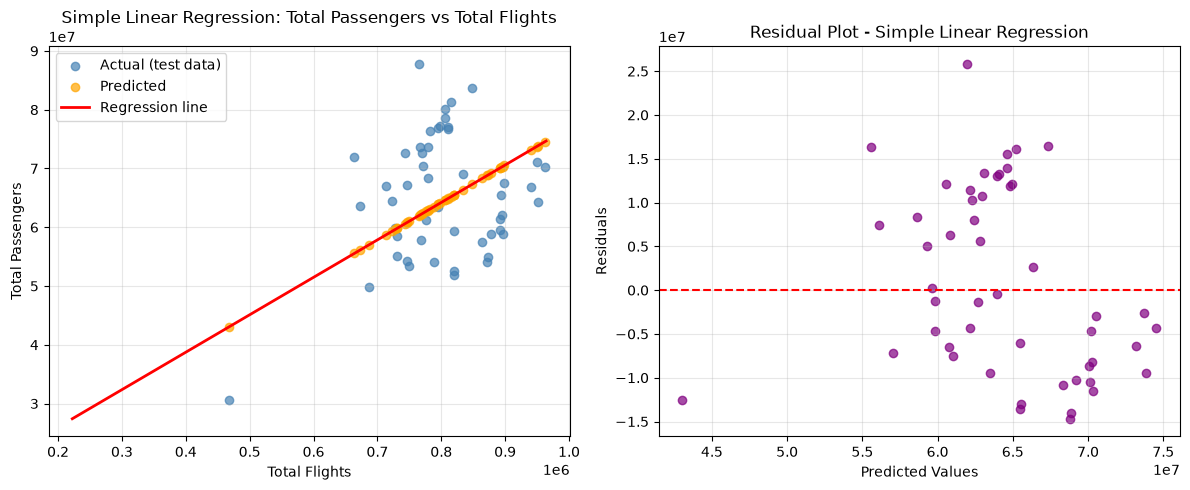

In [10]:
# TODO: Visualize the simple linear regression results
# Create two plots: scatter plot with regression line and residual plot

# Plot 1: Scatter plot with regression line
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_test_simple['Flt'], y_test_simple, color='steelblue', alpha=0.7, label='Actual (test data)')
plt.scatter(X_test_simple['Flt'], y_pred_simple, color='orange', alpha=0.7, label='Predicted')
flights_line = np.linspace(X_simple['Flt'].min(), X_simple['Flt'].max(), 100).reshape(-1, 1)
passengers_line = simple_model.predict(pd.DataFrame(flights_line, columns=['Flt']))
plt.plot(flights_line, passengers_line, color='red', linewidth=2, label='Regression line')

plt.xlabel('Total Flights')
plt.ylabel('Total Passengers')
plt.title('Simple Linear Regression: Total Passengers vs Total Flights')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Residual plot
plt.subplot(1, 2, 2)
# Residuals = actual passengers minus predicted passengers.
# I want them scattered randomly around the zero line. A clear pattern would mean the straight line is missing something.
residuals = y_test_simple - y_pred_simple

plt.scatter(y_pred_simple, residuals, color='purple', alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot - Simple Linear Regression')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**What I see in the simple regression:** On the test months, total flights alone do a poor job of predicting passengers (R² is even slightly negative, so the model is worse than just guessing the average). The residual plot is not random: months with many flights (mostly the early 2000s) are over-predicted, and later months with fewer flights but more passengers are under-predicted. A straight line on the total flight count is missing the trend of more passengers per flight.


## 5. Multiple Linear Regression

In [11]:
# TODO: Build a multiple linear regression model
# Goal: Predict Total Passengers using multiple features
# Hint: Avoid using Pax in features since that's our target (multicollinearity)

print("Multiple Linear Regression: Predicting Total Passengers from Multiple Features")

# Select appropriate features
# The hint suggests Dom_Pax, Int_Pax, Dom_Flt, Int_Flt, Dom_RPM (avoid Pax and Flt).
# But first I check something important: in my data Pax is exactly Dom_Pax + Int_Pax.
pax_is_exact_sum = (df['Dom_Pax'] + df['Int_Pax'] == df['Pax']).all()
print(f"Is Pax exactly Dom_Pax + Int_Pax in every row? {pax_is_exact_sum}")
# Because it is, using Dom_Pax and Int_Pax would "leak" the answer into the model
# (it would just add two columns and get R² = 1.0 without learning anything).
# So I drop those two and keep the other suggested features: flights and domestic passenger-miles.
feature_columns = ['Dom_Flt', 'Int_Flt', 'Dom_RPM']

X_multiple = df[feature_columns]
y_multiple = df['Pax']

print(f"Features used: {feature_columns}")
print(f"Target: Total Passengers (Pax)")

# Split the data (same settings as the simple model, so both are tested on the same months)
X_train_mult, X_test_mult, y_train_mult, y_test_mult = train_test_split(
    X_multiple, y_multiple, test_size=0.2, random_state=42)

# Apply feature scaling
scaler = StandardScaler()
X_train_mult_scaled = scaler.fit_transform(X_train_mult)   # I fit the scaler on the training data only
X_test_mult_scaled = scaler.transform(X_test_mult)         # and only transform the test data

# Create and train the multiple regression model
multiple_model = LinearRegression()
multiple_model.fit(X_train_mult_scaled, y_train_mult)

# Make predictions
y_pred_mult = multiple_model.predict(X_test_mult_scaled)

# Calculate performance metrics
r2_mult = r2_score(y_test_mult, y_pred_mult)
mse_mult = mean_squared_error(y_test_mult, y_pred_mult)
mae_mult = mean_absolute_error(y_test_mult, y_pred_mult)
rmse_mult = np.sqrt(mse_mult)

print(f"\nModel Performance:")
print(f"R² Score: {r2_mult:.4f}")
print(f"Mean Squared Error: {mse_mult:.2f}")
print(f"Root Mean Squared Error: {rmse_mult:.2f}")
print(f"Mean Absolute Error: {mae_mult:.2f}")

# Display feature coefficients
print(f"\nFeature Coefficients (after scaling):")
for feature, coef in zip(feature_columns, multiple_model.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {multiple_model.intercept_:.2f}")

Multiple Linear Regression: Predicting Total Passengers from Multiple Features
Is Pax exactly Dom_Pax + Int_Pax in every row? True
Features used: ['Dom_Flt', 'Int_Flt', 'Dom_RPM']
Target: Total Passengers (Pax)

Model Performance:
R² Score: 0.9940
Mean Squared Error: 664504722185.71
Root Mean Squared Error: 815171.59
Mean Absolute Error: 626549.68

Feature Coefficients (after scaling):
Dom_Flt: 1007181.0478
Int_Flt: 1463338.6079
Dom_RPM: 10838708.5125
Intercept: 61921705.70


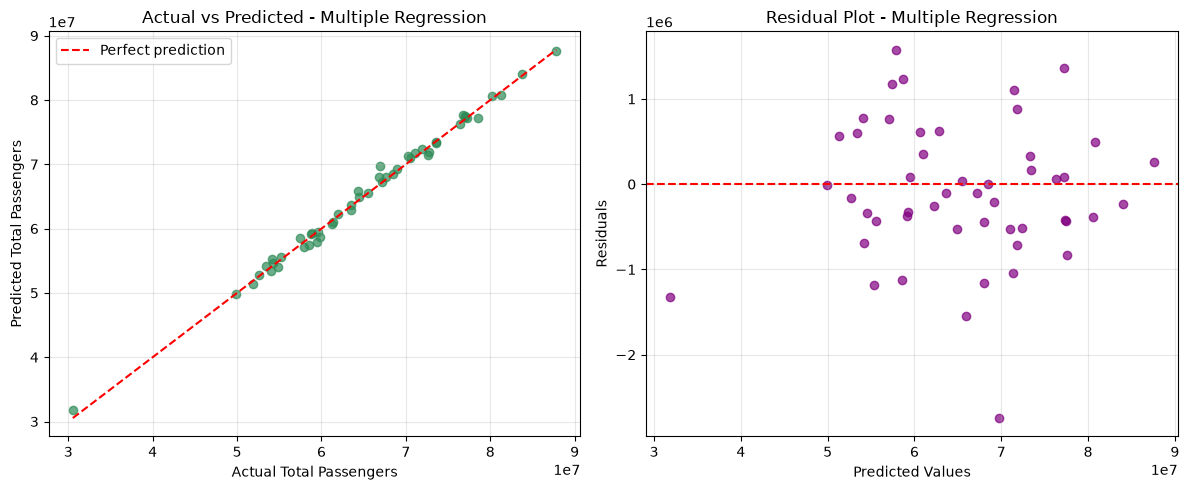

In [12]:
# TODO: Visualize multiple regression results
# Create actual vs predicted plot and residual plot

plt.figure(figsize=(12, 5))

# Plot 1: Actual vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test_mult, y_pred_mult, color='seagreen', alpha=0.7)
# Diagonal reference line (perfect prediction line)
lowest_value = min(y_test_mult.min(), y_pred_mult.min())
highest_value = max(y_test_mult.max(), y_pred_mult.max())
plt.plot([lowest_value, highest_value], [lowest_value, highest_value], 'r--', label='Perfect prediction')
plt.legend()

plt.xlabel('Actual Total Passengers')
plt.ylabel('Predicted Total Passengers')
plt.title('Actual vs Predicted - Multiple Regression')
plt.grid(True, alpha=0.3)

# Plot 2: Residual plot
plt.subplot(1, 2, 2)
residuals_mult = y_test_mult - y_pred_mult

plt.scatter(y_pred_mult, residuals_mult, color='purple', alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot - Multiple Regression')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**What I see in the multiple regression:** Using domestic flights, international flights and domestic passenger-miles, the model is much stronger (R² ≈ 0.99) and the residuals are much smaller and look more randomly scattered around zero. I did not use Dom_Pax or Int_Pax as features, because in this data they add up exactly to Pax in every row and would leak the answer into the model.


## 6. Model Comparison and Analysis

In [13]:
# TODO: Compare the performance of both models
# Create a comparison table and determine which model performs better

print("Model Comparison:")
print("=" * 65)
print(f"{'Metric':<25} {'Simple Regression':<20} {'Multiple Regression':<20}")
print("=" * 65)

# Print comparison of R², RMSE, and MAE
print(f"{'R² Score':<25} {r2_simple:<20.4f} {r2_mult:<20.4f}")
print(f"{'RMSE':<25} {rmse_simple:<20,.0f} {rmse_mult:<20,.0f}")
print(f"{'MAE':<25} {mae_simple:<20,.0f} {mae_mult:<20,.0f}")

print("=" * 65)

# Determine which model performs better based on R² and calculate the improvement percentage
# Improvement % = ((new_value - old_value) / old_value) × 100
# My simple R² is negative, so I divide by its absolute value to keep the sign meaningful.
if r2_mult > r2_simple:
    better_model = "Multiple Regression"
    improvement = (r2_mult - r2_simple) / abs(r2_simple) * 100
else:
    better_model = "Simple Regression"
    improvement = (r2_simple - r2_mult) / abs(r2_mult) * 100

print(f"\nBest Model: {better_model}")
print(f"R² Improvement: {improvement:.2f}%")
print(f"(In plain numbers, R² went from {r2_simple:.4f} to {r2_mult:.4f}, a gain of {r2_mult - r2_simple:.4f}.)")

# For errors, lower is better, so a negative % means the error went down.
rmse_change = (rmse_mult - rmse_simple) / rmse_simple * 100
mae_change = (mae_mult - mae_simple) / mae_simple * 100
print(f"RMSE change: {rmse_change:.2f}%")
print(f"MAE change: {mae_change:.2f}%")

Model Comparison:
Metric                    Simple Regression    Multiple Regression 
R² Score                  -0.0092              0.9940              
RMSE                      10,528,814           815,172             
MAE                       9,262,993            626,550             

Best Model: Multiple Regression
R² Improvement: 10858.13%
(In plain numbers, R² went from -0.0092 to 0.9940, a gain of 1.0032.)
RMSE change: -92.26%
MAE change: -93.24%


## 7. Statistical Insights and Conclusions

In [14]:
# TODO: Summarize your findings and provide insights
# Include results from hypothesis tests, regression analysis, and key findings

print("STATISTICAL INSIGHTS AND CONCLUSIONS")
print("=" * 60)

print("\n1. HYPOTHESIS TESTING RESULTS:")
print(f"   • Domestic vs International Passengers: t = {t_stat:.2f}, p = {p_value:.2e} < 0.05 -> I reject H0. "
      f"Domestic months average {df['Dom_Pax'].mean():,.0f} passengers vs {df['Int_Pax'].mean():,.0f} international.")
print(f"   • Correlation between Total Passengers and Flights: r = {correlation_coef:.3f}, p = {p_value_corr:.2e} < 0.05 -> "
      f"I reject H0. The link is real and positive, but only moderate.")

print("\n2. REGRESSION ANALYSIS:")
print(f"   • Simple Linear Regression R²: {r2_simple:.4f} -> on the test months, flights alone predict passengers "
      f"no better than just using the average (typical error ≈ {mae_simple:,.0f} passengers).")
print(f"   • Multiple Linear Regression R²: {r2_mult:.4f} -> domestic and international flights plus domestic "
      f"passenger-miles explain {r2_mult*100:.1f}% of the variation (typical error ≈ {mae_mult:,.0f} passengers).")
print(f"   • Best performing model: {better_model} (RMSE {rmse_change:.1f}%, MAE {mae_change:.1f}%)")

print("\n3. KEY FINDINGS:")
print(f"   • {len(strong_pairs)} variable pairs have |r| > 0.7; many are just totals and their parts (e.g. Dom_Pax–Pax r = {correlation_matrix.loc['Dom_Pax', 'Pax']:.3f}).")
print(f"   • Total flights are only moderately linked to passengers (r = {correlation_coef:.2f}), "
      f"while Dom_RPM is almost perfectly linked (r = {correlation_matrix.loc['Pax', 'Dom_RPM']:.3f}).")
print(f"   • Domestic traffic dominates: {df['Dom_Pax'].sum() / df['Pax'].sum() * 100:.1f}% of all passengers in this data are domestic.")

print("\n4. RECOMMENDATIONS:")
print("   • To forecast passengers, use passenger-miles and the split of domestic/international flights, not the total flight count alone.")
print("   • Plan capacity separately for domestic and international markets, since their sizes are very different.")
print("   • Treat unusual months (like the 2020 COVID drop) separately before trusting a simple straight-line model.")

STATISTICAL INSIGHTS AND CONCLUSIONS

1. HYPOTHESIS TESTING RESULTS:
   • Domestic vs International Passengers: t = 70.95, p = 7.03e-262 < 0.05 -> I reject H0. Domestic months average 55,209,710 passengers vs 7,392,209 international.
   • Correlation between Total Passengers and Flights: r = 0.570, p = 7.72e-23 < 0.05 -> I reject H0. The link is real and positive, but only moderate.

2. REGRESSION ANALYSIS:
   • Simple Linear Regression R²: -0.0092 -> on the test months, flights alone predict passengers no better than just using the average (typical error ≈ 9,262,993 passengers).
   • Multiple Linear Regression R²: 0.9940 -> domestic and international flights plus domestic passenger-miles explain 99.4% of the variation (typical error ≈ 626,550 passengers).
   • Best performing model: Multiple Regression (RMSE -92.3%, MAE -93.2%)

3. KEY FINDINGS:
   • 81 variable pairs have |r| > 0.7; many are just totals and their parts (e.g. Dom_Pax–Pax r = 0.997).
   • Total flights are only moderat

## 8. Reflection Questions

**Answer the following questions based on your analysis:**

1. **Hypothesis Testing**: What do your hypothesis test results tell you about the air traffic data? Were the results expected?

   **My answer:** Both tests gave p-values far below 0.05, so I rejected both null hypotheses. Test 1 (t = 70.95, p ≈ 7.0e-262): domestic months average about 55.2 million passengers and international months about 7.4 million, so domestic travel is about 7.5 times bigger. This was expected, and here the difference is also huge in practice, not just "statistically significant". (A small note for myself: Dom_Pax and Int_Pax come from the same months, and their spreads are very different, so a paired or Welch t-test would fit a bit better. With a gap this big the conclusion would not change.) Test 2 (r = 0.570, p ≈ 7.7e-23): there is a real positive link between total flights and total passengers, but it is only moderate (r² ≈ 0.32). I expected a stronger link. I think it is weaker because over the years airlines carried more passengers on fewer flights (around 850,000 flights for about 55 million passengers per month in 2003, and around 800,000 flights for about 80 million in 2019).

2. **Model Performance**: Which regression model performed better and why? What does the R² value tell you?

   **My answer:** The multiple regression was much better: R² = 0.9940 against R² = -0.0092 for the simple one. RMSE went down from about 10.5 million to about 0.82 million passengers (-92.3%), and MAE went down from about 9.3 million to about 0.63 million (-93.2%). A negative R² means that on the test months, total flights alone predicted worse than just guessing the average every time. The multiple model wins because Dom_RPM (domestic revenue passenger-miles, r = 0.989 with Pax) carries a lot of information about how many people actually flew, and splitting flights into domestic and international helps too. I did **not** use Dom_Pax and Int_Pax, because in this data Pax = Dom_Pax + Int_Pax in every row. With them the model just adds two columns and gets a "perfect" R² = 1.0, which would be target leakage, not learning.

3. **Correlations**: What were the strongest correlations you found? How might these relationships be useful for airlines?

   **My answer:** 81 of the 136 variable pairs have |r| > 0.7. The strongest are totals with their own parts, for example Dom_Pax–Pax (0.997), Dom_Flt–Flt (0.997) and Dom_LF–LF (0.990), plus passenger-miles with passengers (Pax–Dom_RPM 0.989). These mostly show that the totals are made from the parts, so I should not put a total and its parts in the same model. Interesting for airlines: the number of flights is only moderately linked to passengers (r = 0.57), while seats and passenger-miles (ASM, RPM) are very strongly linked. So the size of the planes and how full they are (load factor) matter more than just adding more flights. Airlines can use this to plan capacity (bigger planes, better load factor) instead of only scheduling more flights.

4. **Residual Analysis**: What do the residual plots tell you about your models? Are there any patterns that suggest model improvements?

   **My answer:** In the simple model the residuals are big (from about -15 million to +26 million passengers) and they are not random. Months with many flights (mostly the early 2000s) are over-predicted, and months with fewer flights but many passengers (mostly the later years) are under-predicted. This pattern tells me a straight line on total flights alone misses something: the time trend of more passengers per flight, and the COVID months of 2020–2021. In the multiple model the residuals are much smaller (mostly within ±1.5 million) and look scattered around zero without a clear shape, so the linear assumption looks much more reasonable there. To improve, I could add Year/Month (trend and seasonality) or treat the COVID period separately.

5. **Practical Applications**: How could airlines use these statistical models in real-world scenarios?

   **My answer:** Airlines and airports could use the multiple model to forecast monthly passenger numbers from planned flights and expected passenger-miles. That helps with staff, gates, fuel and catering planning. The hypothesis tests show that domestic and international markets are very different in size, so they should be planned and priced separately. The correlation results show that load factor and seat capacity drive passenger numbers more than the number of flights, which helps when deciding between more flights and bigger or fuller planes. The residuals can also be used as an alarm: a month with a very large error (like in 2020) means something unusual is happening and the forecast should be checked.